# LightShift-PatchCore — 02 · Lighting Shifts & Diagnostic (CPU)

**Objectif :** réutiliser **sans réentraînement** les banques ResNet-18 du notebook 01 et mesurer comment les changements d'éclairage modifient le **ranking** (AUROC/AP) et la **calibration** (F1/FPR au seuil source).  
**Catégories :** bottle, carpet, metal_nut.  
**Méthode :** MVTec AD original + perturbations photométriques synthétiques déterministes ; *ce n'est pas MVTec AD 2 ni un benchmark MVTec-C officiel*.  
**Règle :** `target_test` reste réservé à l'évaluation ; `target_calibration` n'est **pas utilisé** ici (réservé à B2/B3). Les seuils fixes sont ajustés exclusivement sur `source_val`.

> Pré-requis : avoir terminé le notebook 01, conserver `notebooks/artifacts_baseline/` et `models/*_resnet18_cpu_bank.npy`. Les poids ImageNet doivent être disponibles dans le cache PyTorch (téléchargement au premier usage si nécessaire).

**Plan :** (1) environnement et artefacts, (2) perturbations, (3) seuil source, (4) diagnostic ranking/calibration, (5) dérive statistique, (6) figures, (7) MLflow et sauvegardes.

## Phase A — Recharger exactement la baseline du notebook 01

### Étape 1 — Imports, CPU, seeds et répertoires

In [1]:
from pathlib import Path
import os, json, random, time, platform, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from scipy.ndimage import gaussian_filter
from scipy.stats import spearmanr
from skimage.measure import label, regionprops
import yaml

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cpu')
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
WORKSPACE = Path('/workspace') if Path('/workspace/notebooks').is_dir() else Path.cwd().resolve().parent
NOTEBOOKS_DIR = WORKSPACE / 'notebooks' if (WORKSPACE / 'notebooks').is_dir() else Path.cwd()
BASELINE_DIR = NOTEBOOKS_DIR / 'artifacts_baseline'
BASELINE_CONFIG = NOTEBOOKS_DIR / 'configs' / 'baseline_cpu.yaml'
MODELS_DIR = WORKSPACE / 'models' if (WORKSPACE / 'models').is_dir() else NOTEBOOKS_DIR / 'models'
OUTPUT_DIR = NOTEBOOKS_DIR / 'artifacts_lighting'
for sub in ['', 'figures', 'metrics', 'config']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)
assert BASELINE_CONFIG.is_file(), f'Config du notebook 01 introuvable : {BASELINE_CONFIG}'
CFG = yaml.safe_load(BASELINE_CONFIG.read_text(encoding='utf-8'))
CATEGORIES = CFG['categories']
IMAGE_SIZE = int(CFG['image_size'])
assert CFG['backbone'] == 'resnet18' and CFG['layers'] == ['layer2', 'layer3'], 'Ce notebook reproduit le modèle exact du notebook 01.'
print('Python:', platform.python_version(), '| Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
print('Baseline:', BASELINE_DIR, '| Catégories:', CATEGORIES, '| Taille:', IMAGE_SIZE)

Python: 3.11.18 | Torch: 2.15.0+cu132 | CUDA: False
Baseline: /workspace/notebooks/artifacts_baseline | Catégories: ['bottle', 'carpet', 'metal_nut'] | Taille: 224


### Étape 2 — Charger les splits sauvegardés, vérifier les données et charger les banques `.npy`

In [2]:
def locate_mvtec_root(base, categories):
    base = Path(base)
    candidates = [base, base.parent, WORKSPACE / 'data']
    for root in list(candidates):
        if root.is_dir():
            candidates += [p for p in root.glob('*') if p.is_dir()]
            candidates += [p for p in root.glob('*/*') if p.is_dir()]
    for p in dict.fromkeys(candidates):
        if all((p / cat / 'train' / 'good').is_dir() for cat in categories):
            return p
    return None

MVTEC_ROOT = locate_mvtec_root(CFG['data_root'], CATEGORIES)
assert MVTEC_ROOT is not None, 'Impossible de retrouver le dataset MVTec AD.'
SPLITS, BANKS, KNN = {}, {}, {}
for cat in CATEGORIES:
    manifest = BASELINE_DIR / 'splits' / f'{cat}_splits.json'
    bank_path = MODELS_DIR / f'{cat}_resnet18_cpu_bank.npy'
    assert manifest.is_file(), f'Split introuvable : {manifest}'
    assert bank_path.is_file(), f'Banque introuvable : {bank_path}'
    payload = json.loads(manifest.read_text(encoding='utf-8'))
    SPLITS[cat] = {k: [MVTEC_ROOT / rel for rel in values] for k, values in payload.items()}
    assert set(SPLITS[cat]) == {'source_train','source_val','target_calibration','target_test'}
    allpaths = [str(p.resolve()) for group in SPLITS[cat].values() for p in group]
    assert len(allpaths) == len(set(allpaths)), f'Fuite de données détectée : {cat}'
    assert all(p.is_file() for group in SPLITS[cat].values() for p in group), f'Images manquantes : {cat}'
    BANKS[cat] = np.load(bank_path, allow_pickle=False).astype(np.float32)
    KNN[cat] = NearestNeighbors(n_neighbors=1, algorithm='brute', metric='euclidean', n_jobs=1).fit(BANKS[cat])
display(pd.DataFrame([dict(category=c, **{k:len(v) for k,v in SPLITS[c].items()}, bank_patches=len(BANKS[c])) for c in CATEGORIES]))
print('Données source intactes ; aucun nouveau split créé.')

,category,source_train,source_val,target_calibration,target_test,bank_patches
0,bottle,146,31,32,83,256
1,carpet,196,42,42,117,256
2,metal_nut,154,33,33,115,256


Données source intactes ; aucun nouveau split créé.


### Étape 3 — Recharger le prétraitement et le backbone ResNet-18 gelé

La concaténation de `layer2` et `layer3`, le resize et le lissage correspondent **exactement** au notebook 01.

In [3]:
weights = ResNet18_Weights.DEFAULT
mean, std = weights.transforms().mean, weights.transforms().std
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
mask_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()
])

class FeatureExtractor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = resnet18(weights=weights).to(DEVICE).eval()
        self.features = {}
        self.hooks = []
        for layer_name in CFG['layers']:
            hook = getattr(self.backbone, layer_name).register_forward_hook(
                lambda module, inputs, output, key=layer_name: self.features.__setitem__(key, output)
            )
            self.hooks.append(hook)
        for p in self.backbone.parameters(): p.requires_grad_(False)

    @torch.inference_mode()
    def forward(self, batch):
        self.features.clear()
        self.backbone(batch.to(DEVICE))
        h = self.features['layer2']
        parts = [h]
        for name in CFG['layers']:
            if name != 'layer2':
                parts.append(F.interpolate(self.features[name], size=h.shape[-2:], mode='bilinear', align_corners=False))
        return torch.cat(parts, dim=1)

extractor = FeatureExtractor()
for cat in CATEGORIES:
    with Image.open(SPLITS[cat]['source_val'][0]) as im:
        fm = extractor(image_transform(im.convert('RGB')).unsqueeze(0))
    assert BANKS[cat].shape[1] == fm.shape[1], f'Dimension incompatible pour {cat}'
print('Backbone chargé, dimensions des banques compatibles.')

def load_mask(path, category):
    if path.parent.name == 'good': return np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
    p = MVTEC_ROOT / category / 'ground_truth' / path.parent.name / (path.stem + '_mask.png')
    if not p.is_file(): raise FileNotFoundError(f'Masque manquant : {p}')
    with Image.open(p) as im: mask = mask_transform(im.convert('L')).squeeze(0).numpy()
    return (mask > 0).astype(np.uint8)

Backbone chargé, dimensions des banques compatibles.


## Phase B — Simuler les changements d’éclairage

### Étape 4 — Paramètres du protocole CPU et configuration enregistrée

**Mode par défaut :** 3 catégories × 5 perturbations × 3 sévérités + condition clean. Pour un essai très rapide, réduire `SHIFTS` ou `SEVERITIES` puis réexécuter les cellules suivantes. Ne jamais choisir les meilleurs paramètres en fonction du test.

In [4]:
SHIFTS = ['brightness', 'contrast', 'gamma', 'color_temperature', 'directional_shading']
SEVERITIES = [1, 3, 5]
ALPHA = 0.05  # Quantile source normal : taux d'alerte nominal approximatif, sans garantie conforme
N_DRIFT_VAL = 8  # images normales source_val utilisées pour la dérive, sans regarder target_test
AUPRO_THRESHOLDS = 80  # réduit le temps CPU ; protocole d'approximation explicite
PIXEL_METRICS = True  # mettre False pour un essai de vitesse (puis True pour le rapport)
LOG_TO_MLFLOW = True
SHIFT_CFG = dict(seed=SEED, dataset='MVTec AD (synthétique)', shifts=SHIFTS,
                 severities=SEVERITIES, alpha=ALPHA, drift_val_images=N_DRIFT_VAL,
                 aupro_thresholds=AUPRO_THRESHOLDS, pixel_metrics=PIXEL_METRICS,
                 baseline_config=str(BASELINE_CONFIG), categories=CATEGORIES)
(OUTPUT_DIR / 'config' / 'lighting_cpu.yaml').write_text(yaml.safe_dump(SHIFT_CFG, sort_keys=False, allow_unicode=True),encoding='utf-8')
print('Conditions par catégorie :', 1+len(SHIFTS)*len(SEVERITIES))

Conditions par catégorie : 16


### Étape 5 — Fonctions des perturbations photométriques déterministes

Les transformations sont appliquées **en mémoire uniquement** à l’image RGB. Les masques sont conservés. Pour préserver la reproductibilité, le sens de l’ombre dépend du chemin et de la graine.

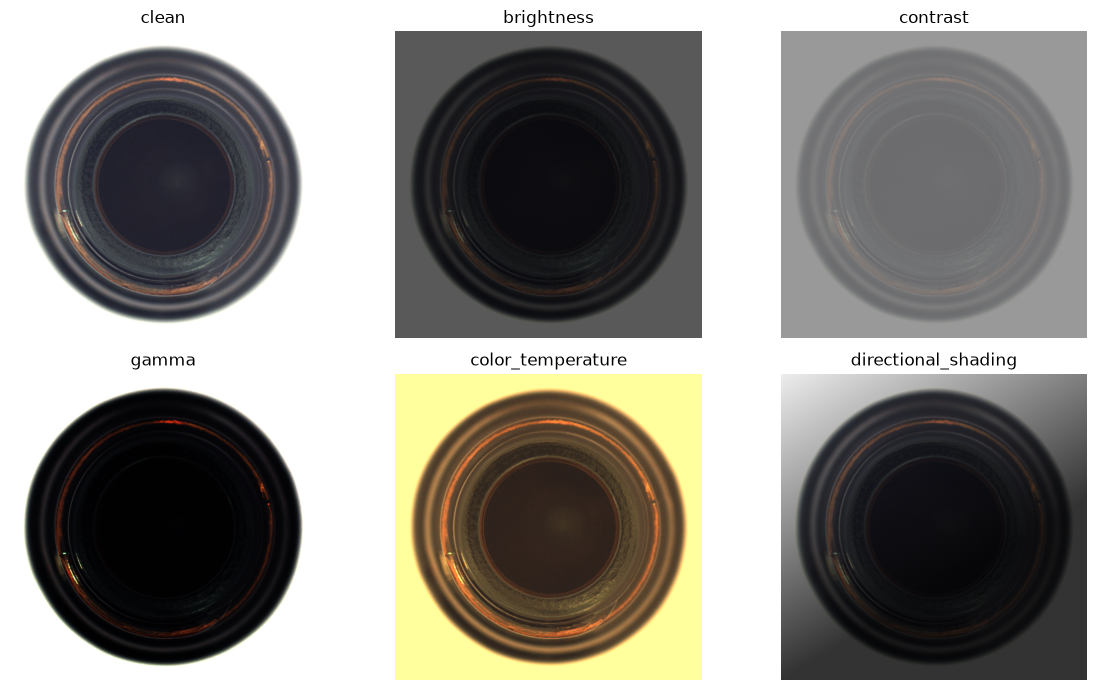

In [5]:
def apply_lighting_shift(rgb_image, kind='clean', severity=0, image_key=''):
    x = np.asarray(rgb_image.convert('RGB'), dtype=np.float32) / 255.0
    if kind == 'clean' or severity == 0: return rgb_image.convert('RGB').copy()
    assert severity in (1, 3, 5), 'Sévérité attendue : 1, 3 ou 5.'
    t = severity / 5.0
    if kind == 'brightness':
        # Assombrissement progressif
        x = x * (1.0 - 0.65 * t)
    elif kind == 'contrast':
        # Contraste réduit autour de 0.5
        x = (x - 0.5) * (1.0 - 0.80 * t) + 0.5
    elif kind == 'gamma':
        x = np.power(x, 1.0 + 1.8 * t)
    elif kind == 'color_temperature':
        gains = np.array([1 + 0.38*t, 1 + 0.04*t, 1 - 0.38*t],dtype=np.float32)
        x = x * gains[None, None, :]
    elif kind == 'directional_shading':
        key = hashlib.sha256(f'{SEED}|{image_key}'.encode()).digest()
        angle = int.from_bytes(key[:4], 'big') / 2**32 * 2 * np.pi
        h,w = x.shape[:2]
        xx = np.linspace(-1, 1, w, dtype=np.float32)[None,:]
        yy = np.linspace(-1, 1, h, dtype=np.float32)[:,None]
        gradient = (xx * np.cos(angle) + yy * np.sin(angle)) / np.sqrt(2)
        factor = np.clip(1.0 - 0.65*t + 0.60*t*gradient, 0.20, 1.15)
        x = x * factor[...,None]
    else: raise ValueError(f'Perturbation inconnue : {kind}')
    return Image.fromarray(np.uint8(np.round(np.clip(x,0,1)*255)), mode='RGB')

with Image.open(SPLITS['bottle']['source_val'][0]) as im:
    original = im.convert('RGB')
    fig, axes = plt.subplots(2,3,figsize=(12,7))
    for ax, kind in zip(axes.flat, ['clean']+SHIFTS):
        ax.imshow(apply_lighting_shift(original,kind,5,'demo_bottle'))
        ax.set_title(kind); ax.axis('off')
    plt.tight_layout(); plt.show()

### Étape 6 — Prédiction PatchCore avec et sans éclairage décalé

Le score image reste le **maximum des distances des patchs**, comme dans le notebook 01.

In [6]:
def feature_to_patches(x):
    return x.squeeze(0).permute(1,2,0).reshape(-1,x.shape[1]).cpu().numpy().astype(np.float32)

@torch.inference_mode()
def predict_path(path, category, shift='clean', severity=0):
    with Image.open(path) as im:
        rgb = apply_lighting_shift(im,shift,severity,str(path.relative_to(MVTEC_ROOT)))
    fmap = extractor(image_transform(rgb).unsqueeze(0))
    h,w = fmap.shape[-2:]
    distances,_ = KNN[category].kneighbors(feature_to_patches(fmap),return_distance=True)
    patch_scores = distances[:,0].reshape(h,w)
    resized = F.interpolate(torch.from_numpy(patch_scores)[None,None],size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0,0].numpy()
    hm = gaussian_filter(resized, float(CFG['pixel_smoothing_sigma'])).astype(np.float32)
    return float(patch_scores.max()), hm

for cat in CATEGORIES:
    score,heatmap = predict_path(SPLITS[cat]['source_val'][0],cat)
    print(cat, 'score:',round(score,4),'heatmap:',heatmap.shape)

bottle score: 3.7266 heatmap: (224, 224)
carpet score: 3.1696 heatmap: (224, 224)
metal_nut score: 4.9114 heatmap: (224, 224)


## Phase C — Calibrer le seuil SOURCE exclusivement sur validation normale

### Étape 7 — Quantile des scores `source_val` (aucun test utilisé)

**Attention :** un seuil au quantile empirique `1−α` sur les normales source ne garantit pas un FPR de 5 % sur les normales décalées. C’est précisément ce que nous voulons mesurer. La recalibration conforme B3 sera étudiée dans un notebook ultérieur.

In [7]:
SOURCE_THRESHOLDS = {}
SOURCE_VAL_SCORES = {}
for cat in CATEGORIES:
    val_paths = SPLITS[cat]['source_val']
    scores = np.array([predict_path(p,cat)[0] for p in tqdm(val_paths,desc=f'Validation source {cat}')],dtype=float)
    assert len(scores) >= 2 and np.isfinite(scores).all()
    SOURCE_VAL_SCORES[cat] = scores
    SOURCE_THRESHOLDS[cat] = float(np.quantile(scores,1-ALPHA))
threshold_file = OUTPUT_DIR / 'config' / 'source_thresholds.json'
threshold_file.write_text(json.dumps({'alpha':ALPHA,'thresholds':SOURCE_THRESHOLDS,'validation_counts':{c:len(SOURCE_VAL_SCORES[c]) for c in CATEGORIES}},indent=2),encoding='utf-8')
display(pd.DataFrame([dict(category=c,n_val=len(SOURCE_VAL_SCORES[c]),source_threshold=SOURCE_THRESHOLDS[c]) for c in CATEGORIES]))

Validation source bottle:   0%|          | 0/31 [00:00<?, ?it/s]

Validation source carpet:   0%|          | 0/42 [00:00<?, ?it/s]

Validation source metal_nut:   0%|          | 0/33 [00:00<?, ?it/s]

,category,n_val,source_threshold
0,bottle,31,4.585290
1,carpet,42,3.590598
2,metal_nut,33,5.414710


## Phase D — Évaluation du ranking et de la calibration sous chaque éclairage

### Étape 8 — Fonction AU-PRO approximative (NumPy 2 : `np.trapezoid`)

Même idée d’intégration jusqu’à FPR=0,30 que dans le notebook 01. La discrétisation des seuils peut légèrement modifier la valeur ; ne pas comparer à ±1 point sans protocole strictement identique.

In [8]:
def compute_aupro(gt_masks, pred_maps, fpr_limit=0.30, thresholds_count=80):
    gt=np.asarray(gt_masks,dtype=bool)
    scores=np.asarray(pred_maps,dtype=np.float32)
    negatives=(~gt).sum()
    if negatives==0: return float('nan')
    components=[]
    for i in range(len(gt)):
        for r in regionprops(label(gt[i],connectivity=2)):
            coords=r.coords
            components.append((i,coords[:,0],coords[:,1]))
    if not components: return float('nan')
    thresholds=np.linspace(float(scores.max())+1e-6,float(scores.min())-1e-6,thresholds_count)
    fprs=[0.0];pros=[0.0]
    for th in thresholds:
        predicted = scores >= th
        fpr = float((predicted & (~gt)).sum()/negatives)
        pro = float(np.mean([predicted[i,ys,xs].mean() for i,ys,xs in components]))
        fprs.append(fpr);pros.append(pro)
        if fpr >= fpr_limit: break
    x=np.asarray(fprs); y=np.asarray(pros)
    order=np.argsort(x); x=x[order]; y=y[order]
    unique=np.unique(x)
    yy=np.asarray([y[x==u].max() for u in unique])
    if unique[-1] < fpr_limit:
        unique=np.append(unique,fpr_limit); yy=np.append(yy,yy[-1])
    grid=np.unique(np.concatenate(([0.0,fpr_limit],unique[(unique>0)&(unique<fpr_limit)])))
    return float(np.trapezoid(np.interp(grid,unique,yy),grid)/fpr_limit)

print('AU-PRO : fonction chargée.')

AU-PRO : fonction chargée.


### Étape 9 — Exécuter les expériences sur `target_test` (jamais pour régler le seuil)

Chaque condition conserve les **mêmes images de test** et les **mêmes masques**. Résultats : AUROC, AP, F1 et FPR au seuil source, AUROC pixel et AU-PRO. Cette étape est la plus longue sur CPU ; les résultats sont sauvegardés après chaque condition pour éviter de les perdre.

In [9]:
RESULTS_PATH = OUTPUT_DIR / 'metrics' / 'lighting_results.csv'
CONDITIONS = [('clean',0)] + [(kind,s) for kind in SHIFTS for s in SEVERITIES]
RESULTS = []

for cat in CATEGORIES:
    test_paths = SPLITS[cat]['target_test']
    labels = np.array([int(p.parent.name != 'good') for p in test_paths],dtype=int)
    masks = np.stack([load_mask(p,cat) for p in test_paths]) if PIXEL_METRICS else None
    for kind,sev in CONDITIONS:
        started = time.perf_counter()
        image_scores, pred_maps = [], []
        for p in tqdm(test_paths,desc=f'{cat} | {kind} | {sev}',leave=False):
            score,hm = predict_path(p,cat,kind,sev)
            image_scores.append(score)
            if PIXEL_METRICS: pred_maps.append(hm)
        image_scores=np.asarray(image_scores,dtype=np.float32)
        predicted = (image_scores >= SOURCE_THRESHOLDS[cat]).astype(int)
        normal = labels==0
        item = dict(category=cat, shift=kind, severity=sev, n_test=len(labels),
                    image_AUROC=float(roc_auc_score(labels,image_scores)),
                    image_AP=float(average_precision_score(labels,image_scores)),
                    F1_at_source_threshold=float(f1_score(labels,predicted,zero_division=0)),
                    FPR_at_source_threshold=float(predicted[normal].mean()),
                    source_threshold=float(SOURCE_THRESHOLDS[cat]),
                    mean_normal_score=float(image_scores[normal].mean()),
                    mean_anomaly_score=float(image_scores[~normal].mean()),
                    eval_seconds=round(time.perf_counter()-started,2))
        if PIXEL_METRICS:
            maps=np.stack(pred_maps)
            item['pixel_AUROC']=float(roc_auc_score(masks.ravel(),maps.ravel()))
            item['pixel_AUPRO']=compute_aupro(masks,maps,thresholds_count=AUPRO_THRESHOLDS)
        else:
            item['pixel_AUROC']=np.nan; item['pixel_AUPRO']=np.nan
        RESULTS.append(item)
        pd.DataFrame(RESULTS).to_csv(RESULTS_PATH,index=False)
        print(cat,kind,sev,'AUROC',round(item['image_AUROC'],4),'FPR',round(item['FPR_at_source_threshold'],4))

RESULTS_DF=pd.DataFrame(RESULTS)
display(RESULTS_DF.head())
print(f'{len(RESULTS_DF)} conditions enregistrées dans : {RESULTS_PATH}')

bottle | clean | 0:   0%|          | 0/83 [00:00<?, ?it/s]

bottle clean 0 AUROC 0.9762 FPR 0.1


bottle | brightness | 1:   0%|          | 0/83 [00:00<?, ?it/s]

bottle brightness 1 AUROC 0.9738 FPR 0.1


bottle | brightness | 3:   0%|          | 0/83 [00:00<?, ?it/s]

bottle brightness 3 AUROC 0.9817 FPR 0.1


... (88 outputs left out)

metal_nut | directional_shading | 5:   0%|          | 0/115 [00:00<?, ?it/s]

metal_nut directional_shading 5 AUROC 0.6491 FPR 0.1364


,category,shift,severity,n_test,image_AUROC,image_AP,F1_at_source_threshold,FPR_at_source_threshold,source_threshold,mean_normal_score,mean_anomaly_score,eval_seconds,pixel_AUROC,pixel_AUPRO
0,bottle,clean,0,83,0.976190,0.991321,0.968254,0.1,4.58529,3.891865,6.035213,8.01,0.975430,0.941579
1,bottle,brightness,1,83,0.973810,0.990247,0.960000,0.1,4.58529,3.825327,5.935595,9.30,0.972671,0.937432
2,bottle,brightness,3,83,0.981746,0.993849,0.943089,0.1,4.58529,4.011076,5.746403,7.96,0.960501,0.919007
3,bottle,brightness,5,83,0.967460,0.991263,0.863014,1.0,4.58529,4.758030,5.597657,9.02,0.920794,0.859226
4,bottle,contrast,1,83,0.980952,0.993505,0.960000,0.1,4.58529,3.800018,5.867436,9.16,0.972699,0.937364


48 conditions enregistrées dans : /workspace/notebooks/artifacts_lighting/metrics/lighting_results.csv


### Étape 10 — Comparaison au clean : différences de ranking et de calibration

Une forte augmentation du FPR avec un AUROC stable indiquerait une dérive de **calibration** plutôt qu’une forte perte de **ranking**. Il s’agit d’une hypothèse testée, pas d’un résultat présupposé.

In [10]:
baseline_clean=RESULTS_DF.loc[RESULTS_DF['shift']=='clean'].set_index('category')
COMPARISON=RESULTS_DF.copy()
for metric in ['image_AUROC','image_AP','F1_at_source_threshold','FPR_at_source_threshold','pixel_AUROC','pixel_AUPRO']:
    COMPARISON['delta_'+metric] = COMPARISON.apply(lambda r: r[metric]-baseline_clean.loc[r['category'],metric],axis=1)
COMPARISON_PATH=OUTPUT_DIR/'metrics'/'lighting_vs_clean.csv'
COMPARISON.to_csv(COMPARISON_PATH,index=False)
display(COMPARISON[['category','shift','severity','image_AUROC','delta_image_AUROC','FPR_at_source_threshold','delta_FPR_at_source_threshold','F1_at_source_threshold']].head(20))

,category,shift,severity,image_AUROC,delta_image_AUROC,FPR_at_source_threshold,delta_FPR_at_source_threshold,F1_at_source_threshold
0,bottle,clean,0,0.976190,0.000000e+00,0.100000,0.000000,0.968254
1,bottle,brightness,1,0.973810,-2.380952e-03,0.100000,0.000000,0.960000
2,bottle,brightness,3,0.981746,5.555556e-03,0.100000,0.000000,0.943089
3,bottle,brightness,5,0.967460,-8.730159e-03,1.000000,0.900000,0.863014
4,bottle,contrast,1,0.980952,4.761905e-03,0.100000,0.000000,0.960000
5,bottle,contrast,3,0.988095,1.190476e-02,0.100000,0.000000,0.943089
6,bottle,contrast,5,0.973810,-2.380952e-03,0.000000,-0.100000,0.904348
7,bottle,gamma,1,0.984127,7.936508e-03,0.150000,0.050000,0.960630
8,bottle,gamma,3,0.975397,-7.936508e-04,0.150000,0.050000,0.952381
9,bottle,gamma,5,0.950794,-2.539683e-02,0.400000,0.300000,0.907692


## Phase E — Analyser la dérive des caractéristiques internes

### Étape 11 — Statistiques des canaux de `layer2` et `layer3` sur la VALIDATION normale

Mesurer pour chaque image de `source_val` les moyennes et les écarts-types des canaux sous éclairage original/décalé. Le test reste inutilisé pour estimer les statistiques de référence. Il s’agit d’une analyse **appariée** descriptive, non de l’alignement B2.

In [11]:
@torch.inference_mode()
def get_layer_stats(path, kind='clean',severity=0):
    with Image.open(path) as im:
        rgb=apply_lighting_shift(im,kind,severity,str(path.relative_to(MVTEC_ROOT)))
    _=extractor(image_transform(rgb).unsqueeze(0))
    out={}
    for name in CFG['layers']:
        f=extractor.features[name].detach().cpu().numpy()[0]
        out[name]=(f.mean(axis=(1,2)),f.std(axis=(1,2)))
    return out

DRIFT_ROWS=[]
for cat in CATEGORIES:
    val_paths=SPLITS[cat]['source_val'][:N_DRIFT_VAL]
    clean_stats={str(p):get_layer_stats(p) for p in tqdm(val_paths,desc=f'Stats source {cat}',leave=False)}
    for kind,sev in CONDITIONS:
        for layer_name in CFG['layers']:
            deltas_mu=[]; deltas_sd=[]
            for p in val_paths:
                base_mu,base_sd=clean_stats[str(p)][layer_name]
                changed_mu,changed_sd=get_layer_stats(p,kind,sev)[layer_name]
                deltas_mu.append(float(np.linalg.norm(changed_mu-base_mu)/np.sqrt(len(base_mu))))
                deltas_sd.append(float(np.linalg.norm(changed_sd-base_sd)/np.sqrt(len(base_sd))))
            DRIFT_ROWS.append(dict(category=cat,shift=kind,severity=sev,layer=layer_name,
                                   mean_drift=float(np.mean(deltas_mu)),std_drift=float(np.mean(deltas_sd)),
                                   n_val=len(val_paths)))
DRIFT_DF=pd.DataFrame(DRIFT_ROWS)
DRIFT_DF.to_csv(OUTPUT_DIR/'metrics'/'feature_drift_validation.csv',index=False)
display(DRIFT_DF.head(12))

Stats source bottle:   0%|          | 0/8 [00:00<?, ?it/s]

Stats source carpet:   0%|          | 0/8 [00:00<?, ?it/s]

Stats source metal_nut:   0%|          | 0/8 [00:00<?, ?it/s]

,category,shift,severity,layer,mean_drift,std_drift,n_val
0,bottle,clean,0,layer2,0.000000,0.000000,8
1,bottle,clean,0,layer3,0.000000,0.000000,8
2,bottle,brightness,1,layer2,0.019828,0.021525,8
3,bottle,brightness,1,layer3,0.013593,0.015664,8
4,bottle,brightness,3,layer2,0.033149,0.035974,8
5,bottle,brightness,3,layer3,0.025417,0.026598,8
6,bottle,brightness,5,layer2,0.044805,0.049220,8
7,bottle,brightness,5,layer3,0.038047,0.036788,8
8,bottle,contrast,1,layer2,0.016637,0.018003,8
9,bottle,contrast,1,layer3,0.012565,0.013497,8


### Étape 12 — Corrélation exploratoire dérive ↔ performance

Corrélation de Spearman entre dérive moyenne des canaux mesurée sur `source_val` et baisse d’AUROC sur les conditions évaluées. **Interprétation exploratoire uniquement** : les conditions ne sont pas statistiquement indépendantes et cette analyse ne sert pas à choisir les hyperparamètres.

In [12]:
CORR_TABLE=[]
merged=DRIFT_DF.merge(COMPARISON[['category','shift','severity','delta_image_AUROC','delta_FPR_at_source_threshold']],on=['category','shift','severity'],how='inner')
for cat in CATEGORIES:
    for lay in CFG['layers']:
        sub=merged[(merged.category==cat)&(merged.layer==lay)&(merged['shift']!='clean')]
        rho_auc,p_auc=spearmanr(sub['mean_drift'],sub['delta_image_AUROC'])
        rho_fpr,p_fpr=spearmanr(sub['mean_drift'],sub['delta_FPR_at_source_threshold'])
        CORR_TABLE.append(dict(category=cat,layer=lay,rho_drift_vs_delta_AUROC=float(rho_auc),p_auc=float(p_auc),
                               rho_drift_vs_delta_FPR=float(rho_fpr),p_fpr=float(p_fpr)))
CORR_DF=pd.DataFrame(CORR_TABLE)
CORR_DF.to_csv(OUTPUT_DIR/'metrics'/'drift_correlations.csv',index=False)
display(CORR_DF)

,category,layer,rho_drift_vs_delta_AUROC,p_auc,rho_drift_vs_delta_FPR,p_fpr
0,bottle,layer2,-0.550985,3.327381e-02,0.265632,0.338629
1,bottle,layer3,-0.597496,1.866485e-02,0.312166,0.257331
2,carpet,layer2,-0.974084,9.005445e-10,0.909826,0.000003
3,carpet,layer3,-0.977659,3.461442e-10,0.887903,0.000010
4,metal_nut,layer2,-0.673816,5.882295e-03,0.489645,0.063935
5,metal_nut,layer3,-0.731010,1.960240e-03,0.439055,0.101561


## Phase F — Figures explicatives et tableaux

### Étape 13 — Courbes AUROC/FPR en fonction de la sévérité

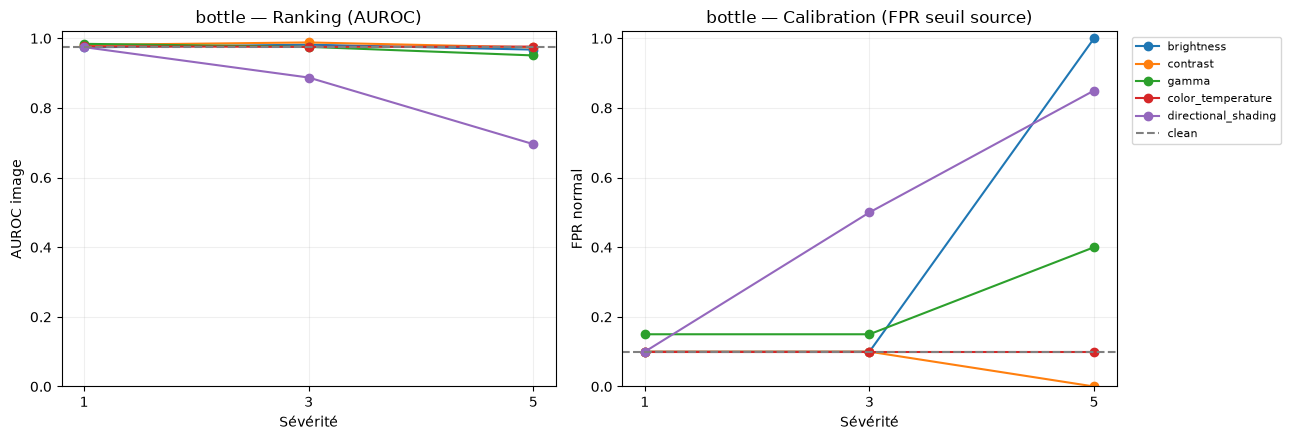

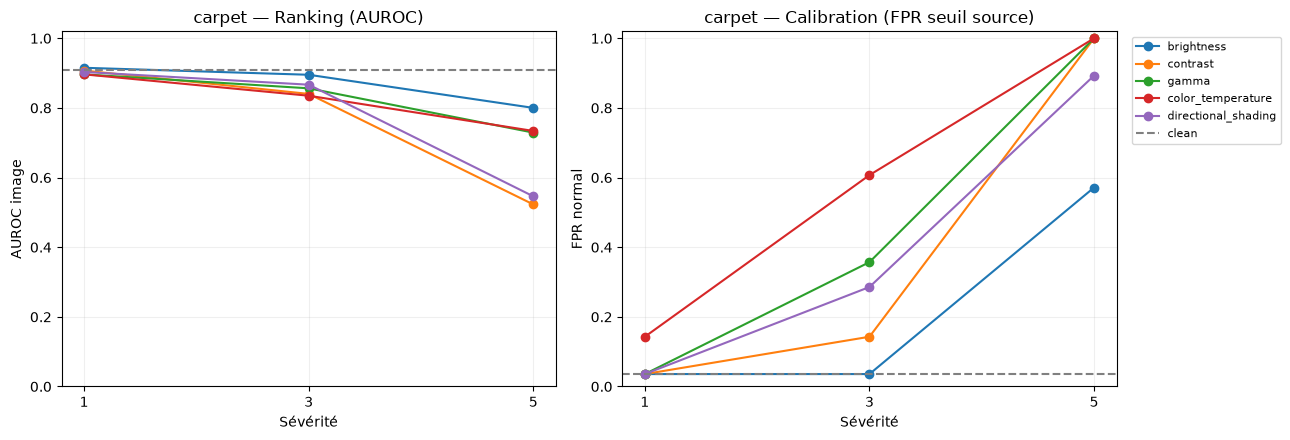

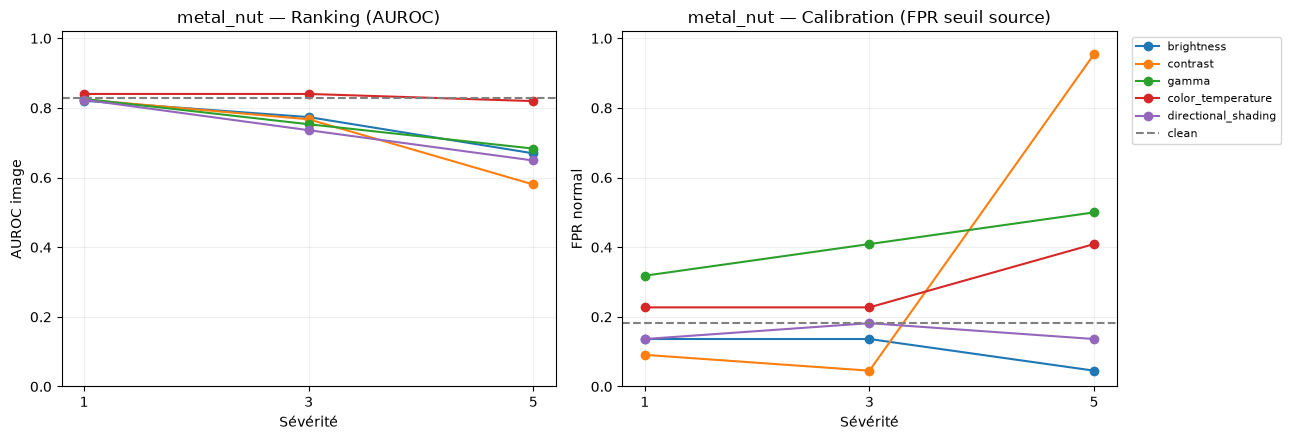

In [13]:
for cat in CATEGORIES:
    sub=COMPARISON[(COMPARISON.category==cat)&(COMPARISON['shift']!='clean')]
    fig,axes=plt.subplots(1,2,figsize=(13,4.5))
    for kind in SHIFTS:
        v=sub[sub['shift']==kind].sort_values('severity')
        axes[0].plot(v['severity'],v['image_AUROC'],marker='o',label=kind)
        axes[1].plot(v['severity'],v['FPR_at_source_threshold'],marker='o',label=kind)
    axes[0].axhline(baseline_clean.loc[cat,'image_AUROC'],ls='--',color='grey',label='clean')
    axes[1].axhline(baseline_clean.loc[cat,'FPR_at_source_threshold'],ls='--',color='grey',label='clean')
    axes[0].set(title=f'{cat} — Ranking (AUROC)',xlabel='Sévérité',ylabel='AUROC image',ylim=(0,1.02))
    axes[1].set(title=f'{cat} — Calibration (FPR seuil source)',xlabel='Sévérité',ylabel='FPR normal',ylim=(0,1.02))
    for ax in axes: ax.grid(alpha=.2); ax.set_xticks(SEVERITIES)
    axes[1].legend(fontsize=8,bbox_to_anchor=(1.02,1),loc='upper left')
    plt.tight_layout()
    path=OUTPUT_DIR/'figures'/f'{cat}_ranking_vs_calibration.png'
    fig.savefig(path,dpi=145,bbox_inches='tight')
    plt.show(); plt.close(fig)

### Étape 14 — Comparaison visuelle heatmaps : clean vs éclairage fort

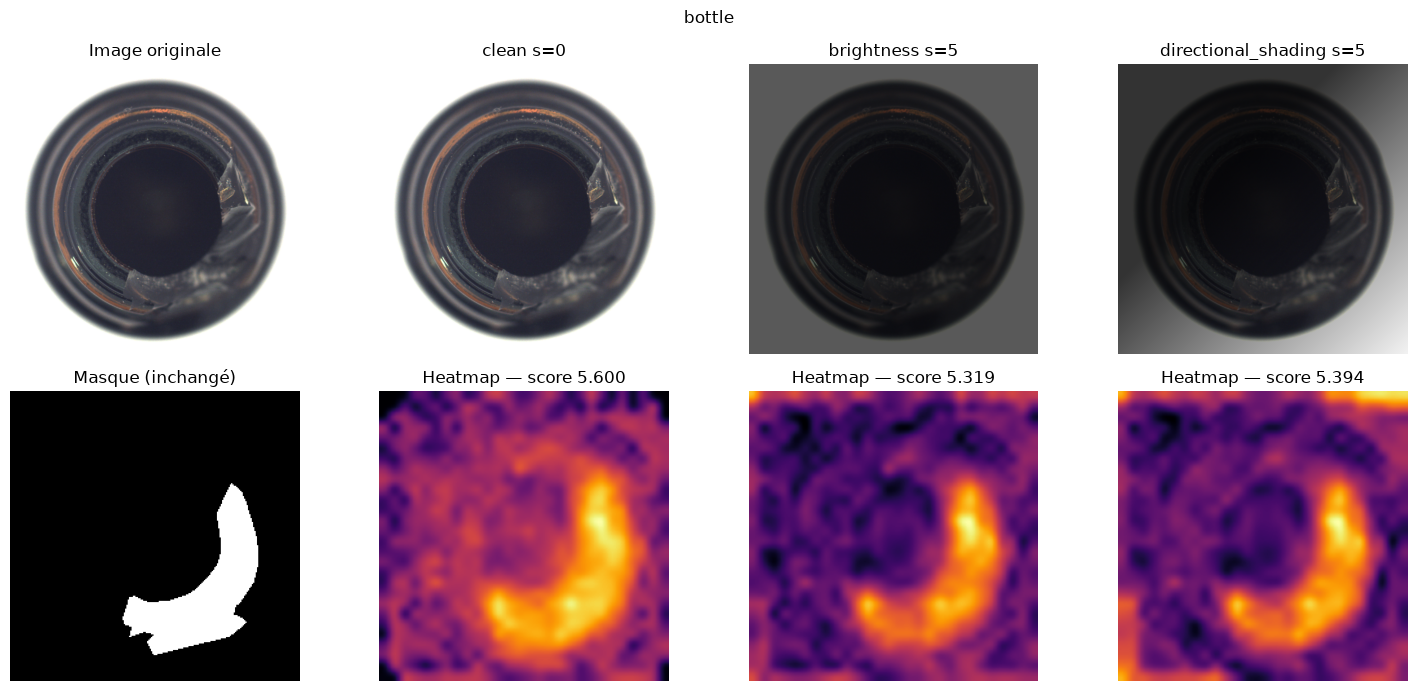

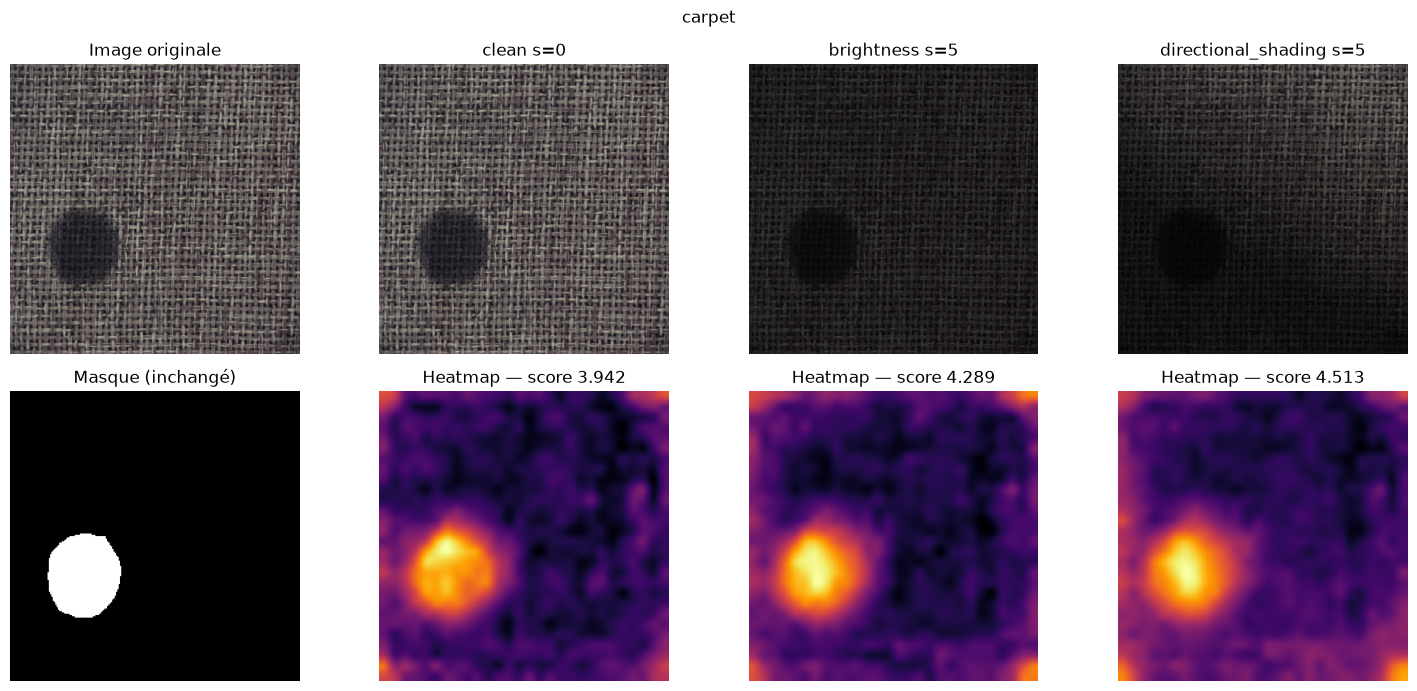

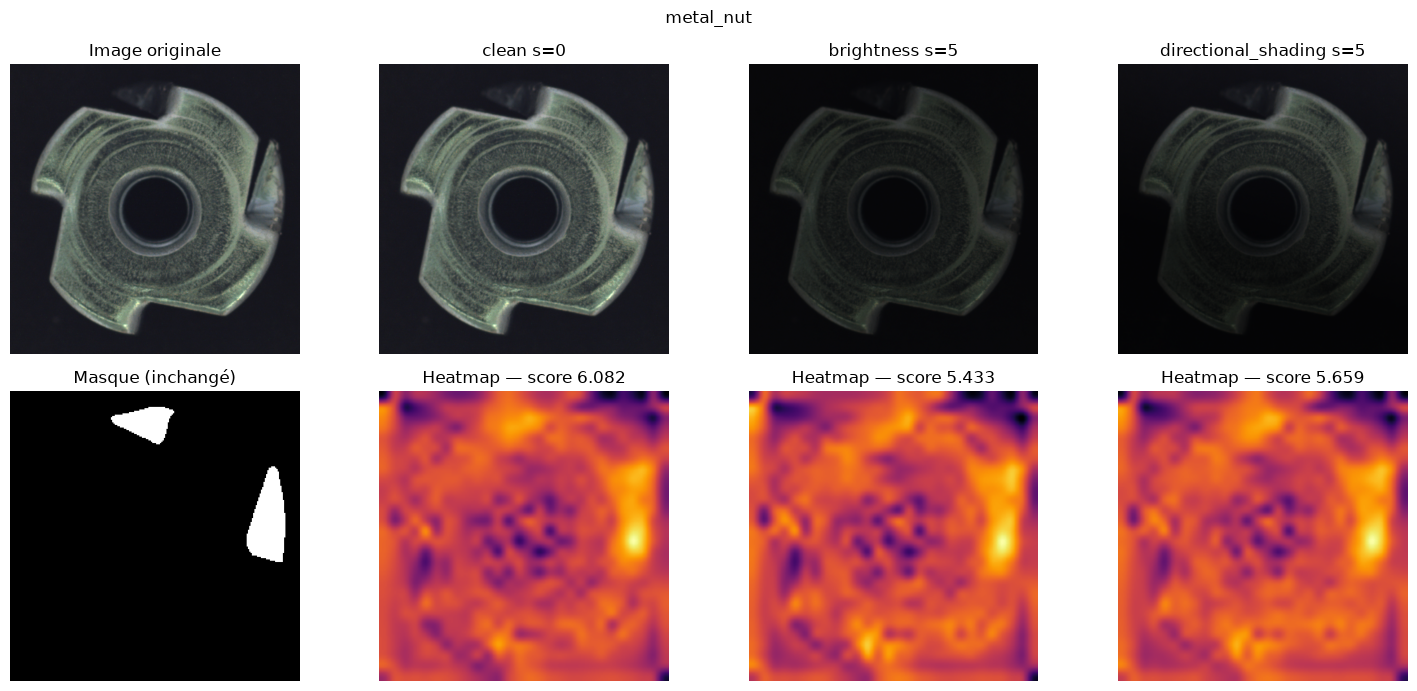

In [14]:
for cat in CATEGORIES:
    defective=next(p for p in SPLITS[cat]['target_test'] if p.parent.name!='good')
    fig,axes=plt.subplots(2,4,figsize=(15,7))
    with Image.open(defective) as im: original=im.convert('RGB')
    axes[0,0].imshow(original);axes[0,0].set_title('Image originale')
    axes[1,0].imshow(load_mask(defective,cat),cmap='gray');axes[1,0].set_title('Masque (inchangé)')
    for j,(kind,sev) in enumerate([('clean',0),('brightness',5),('directional_shading',5)],start=1):
        image=apply_lighting_shift(original,kind,sev,str(defective.relative_to(MVTEC_ROOT)))
        score,hm=predict_path(defective,cat,kind,sev)
        axes[0,j].imshow(image);axes[0,j].set_title(f'{kind} s={sev}')
        axes[1,j].imshow(hm,cmap='inferno');axes[1,j].set_title(f'Heatmap — score {score:.3f}')
    for ax in axes.flat: ax.axis('off')
    fig.suptitle(cat);fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'figures'/f'{cat}_lighting_heatmaps.png',dpi=140,bbox_inches='tight')
    plt.show();plt.close(fig)

## Phase G — MLflow, sauvegarde et bilan

### Étape 15 — Enregistrer chaque condition comme un nouveau run MLflow

Les runs sont **distincts** des runs baseline du notebook 01. Chaque run contient les paramètres de perturbation, le seuil source fixé et les métriques. Si MLflow est indisponible, les CSV et figures restent disponibles localement.

In [15]:
if LOG_TO_MLFLOW:
    import mlflow
    MLFLOW_URI=os.getenv('MLFLOW_TRACKING_URI') or (OUTPUT_DIR/'mlruns').resolve().as_uri()
    mlflow.set_tracking_uri(MLFLOW_URI)
    try:
        mlflow.set_experiment('LightShift-PatchCore-Lighting-CPU')
        for item in tqdm(RESULTS,desc='Enregistrement MLflow'):
            cat=item['category'];kind=item['shift'];sev=item['severity']
            with mlflow.start_run(run_name=f'{cat}_{kind}_s{sev}'):
                mlflow.set_tags({'method':'PatchCore Vanilla','stage':'lighting_diagnostic','dataset':'MVTec AD synthétique'})
                mlflow.log_params({'category':cat,'shift':kind,'severity':sev,'seed':SEED,
                                  'backbone':CFG['backbone'],'image_size':IMAGE_SIZE,
                                  'alpha_source':ALPHA,'threshold_source':SOURCE_THRESHOLDS[cat],
                                  'coreset_size':CFG['coreset_size'],'aupro_thresholds':AUPRO_THRESHOLDS})
                mlflow.log_metrics({k:float(v) for k,v in item.items()
                                    if k not in ('category','shift','severity') and isinstance(v,(float,int,np.number)) and np.isfinite(v)})
                mlflow.log_artifact(str(OUTPUT_DIR/'config'/'lighting_cpu.yaml'),artifact_path='config')
                if kind == 'clean':
                    fig_path=OUTPUT_DIR/'figures'/f'{cat}_ranking_vs_calibration.png'
                    if fig_path.is_file():mlflow.log_artifact(str(fig_path),artifact_path='figures')
        print('Expériences MLflow enregistrées :',MLFLOW_URI)
    except Exception as exc:
        warnings.warn(f'MLflow indisponible : {type(exc).__name__}: {exc}. CSV/figures déjà sauvegardés.')
else:
    print('MLflow désactivé ; résultats CSV et figures sauvegardés.')

2026/11/08 20:51:17 INFO mlflow.tracking.fluent: Experiment with name 'LightShift-PatchCore-Lighting-CPU' does not exist. Creating a new experiment.


Enregistrement MLflow:   0%|          | 0/48 [00:00<?, ?it/s]

🏃 View run bottle_clean_s0 at: http://mlflow:5000/#/experiments/2/runs/0651e25152a34f7c9bd1756391a6f38b
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bottle_brightness_s1 at: http://mlflow:5000/#/experiments/2/runs/43662aebff3f47de89f150da0c5d5208
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bottle_brightness_s3 at: http://mlflow:5000/#/experiments/2/runs/eacb7233baae4963ae1948fe1c39fb10
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bottle_brightness_s5 at: http://mlflow:5000/#/experiments/2/runs/2848c177acbf42b99bd376c13a3f391f
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bottle_contrast_s1 at: http://mlflow:5000/#/experiments/2/runs/a14a2f0497394c829c118b9deed3891b
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bottle_contrast_s3 at: http://mlflow:5000/#/experiments/2/runs/d6d143d49228484485fe77a273d025af
🧪 View experiment at: http://mlflow:5000/#/experiments/2
🏃 View run bo

### Étape 16 — Synthèse du diagnostic, fichiers de sortie et prochaine étape

In [16]:
SUMMARY={
    'baseline_config':CFG,
    'lighting_config':SHIFT_CFG,
    'mvtec_root':str(MVTEC_ROOT),
    'versions':{'python':platform.python_version(),'torch':torch.__version__,'torchvision':torchvision.__version__,'numpy':np.__version__},
    'source_thresholds':SOURCE_THRESHOLDS,
    'results_csv':str(RESULTS_PATH),
    'comparison_csv':str(COMPARISON_PATH),
    'feature_drift_csv':str(OUTPUT_DIR/'metrics'/'feature_drift_validation.csv')
}
(OUTPUT_DIR/'metrics'/'diagnostic_summary.json').write_text(json.dumps(SUMMARY,indent=2,default=str),encoding='utf-8')
assert len(RESULTS_DF)==len(CATEGORIES)*len(CONDITIONS)
assert all(np.isfinite(list(SOURCE_THRESHOLDS.values())))
assert set(CATEGORIES)==set(RESULTS_DF['category'])
print('✅ Baseline rechargée sans réentraînement')
print('✅ Seuils fixés sur source_val uniquement')
print('✅ Test utilisé seulement pour l’évaluation')
print('✅ Résultats :',RESULTS_PATH)
print('✅ Analyse de dérive et figures :',OUTPUT_DIR)
print('➡️ Prochain notebook : 03_statistical_alignment_conformal_calibration.ipynb — B2 + B3')

✅ Baseline rechargée sans réentraînement
✅ Seuils fixés sur source_val uniquement
✅ Test utilisé seulement pour l’évaluation
✅ Résultats : /workspace/notebooks/artifacts_lighting/metrics/lighting_results.csv
✅ Analyse de dérive et figures : /workspace/notebooks/artifacts_lighting
➡️ Prochain notebook : 03_statistical_alignment_conformal_calibration.ipynb — B2 + B3
